In [25]:
import matplotlib.pyplot as plt
import numpy as np
from dataclasses import replace
from IPython.display import clear_output
import pandas as pd
from astropy.table import Table

import run_config
import utils_lya_halo

from run_config import cfg, smoke
from utils_lya_halo import (run_extract, run_stack, read_galaxy_fits, measure, plotting, analysis, multicat,
core, PipelineConfig, stack, selection, fitting, formatting, virial)
from utils_lya_halo.io import read_galaxy_fits, apply_finite_cut
from utils_lya_halo.measure import measure_all_bins, integrated_line_flux
from utils_lya_halo.stack import build_stacks

%matplotlib inline

LYA_REST = PipelineConfig.LYA_REST

import warnings
from astropy.utils.exceptions import AstropyUserWarning

warnings.filterwarnings(
    "ignore",
    message="Input data contains invalid values.*",
    category=AstropyUserWarning,
)

In [26]:
catalog = Table.read('catalogs/lya_halo_catalog_cuts/lya_mosdef_catalog_KEEP.fits', format='fits')
catalog[:5]

INDEX,FIELD,CATALOG,ID,ID_V21,ID_V41,MASKNAME,SLITOBJNAME,RA,DEC,z,Z_QUAL,HA_FLUX,HA_FLUX_ERR,HA_FWHM,HA_FWHM_ERR,HB_FLUX,HB_FLUX_ERR,HB_FWHM,HB_FWHM_ERR,HG_FLUX,HG_FLUX_ERR,HG_FWHM,HG_FWHM_ERR,HD_FLUX,HD_FLUX_ERR,HD_FWHM,HD_FWHM_ERR,OII3727_FLUX,OII3727_FLUX_ERR,OII3727_FWHM,OII3727_FWHM_ERR,OII3730_FLUX,OII3730_FLUX_ERR,OII3730_FWHM,OII3730_FWHM_ERR,OIII4364_FLUX,OIII4364_FLUX_ERR,OIII4364_FWHM,OIII4364_FWHM_ERR,OIII4960_FLUX,OIII4960_FLUX_ERR,OIII4960_FWHM,OIII4960_FWHM_ERR,OIII5008_FLUX,OIII5008_FLUX_ERR,OIII5008_FWHM,OIII5008_FWHM_ERR,OI6302_FLUX,OI6302_FLUX_ERR,OI6302_FWHM,OI6302_FWHM_ERR,NII6550_FLUX,NII6550_FLUX_ERR,NII6550_FWHM,NII6550_FWHM_ERR,NII6585_FLUX,NII6585_FLUX_ERR,NII6585_FWHM,NII6585_FWHM_ERR,SII6718_FLUX,SII6718_FLUX_ERR,SII6718_FWHM,SII6718_FWHM_ERR,SII6733_FLUX,SII6733_FLUX_ERR,SII6733_FWHM,SII6733_FWHM_ERR,NEIII3870_FLUX,NEIII3870_FLUX_ERR,NEIII3870_FWHM,NEIII3870_FWHM_ERR,NEIII3969_FLUX,NEIII3969_FLUX_ERR,NEIII3969_FWHM,NEIII3969_FWHM_ERR,NIIHA,NIIHA_ERR,MASS_50,MASS_16,MASS_84,SFR_50,SFR_16,SFR_84,SSFR_50,SSFR_16,SSFR_84,AV_50,AV_16,AV_84,AGE_50,AGE_16,AGE_84,TAU_50,TAU_16,TAU_84,CHI2,ZFAST,EBV_STAR_16,EBV_STAR_50,EBV_STAR_84,HA_SN,HA_FLAG,HB_SN,HB_FLAG,HG_SN,HG_FLAG,HD_SN,HD_FLAG,OII3727_SN,OII3727_FLAG,OII3730_SN,OII3730_FLAG,OIII4364_SN,OIII4364_FLAG,OIII4960_SN,OIII4960_FLAG,OIII5008_SN,OIII5008_FLAG,OI6302_SN,OI6302_FLAG,NII6550_SN,NII6550_FLAG,NII6585_SN,NII6585_FLAG,SII6718_SN,SII6718_FLAG,SII6733_SN,SII6733_FLAG,NEIII3870_SN,NEIII3870_FLAG,NEIII3969_SN,NEIII3969_FLAG,O3,O3_ERR,O32,O32_ERR,EBV_NEB_16,EBV_NEB_50,EBV_NEB_84,FLUX_RADIUS,A_IMAGE,B_IMAGE,THETA_J2000,KRON_RADIUS,FWHM_IMAGE,CLASS_STAR,F_F160W,E_F160W,F_F814W,E_F814W,F_F606W,E_F606W,F_G,E_G,F_R,E_R,F_V,E_V,F_IRAC1,E_IRAC1,IRAC1_CONTAM,F_IRAC2,E_IRAC2,IRAC2_CONTAM,F_IRAC3,E_IRAC3,IRAC3_CONTAM,F_IRAC4,E_IRAC4,IRAC4_CONTAM,USE_PHOT,STAR_FLAG,PHOT_FLAGS,Z_SPEC,TOT_COR,SKELTON_MATCH,BA,INCL_DEG,GALFIT_FLAG_F160W,GALFIT_MAG_F160W,GALFIT_MAG_ERR_F160W,RE_F160W,RE_ERR_F160W,N_F160W,N_ERR_F160W,Q_F160W,Q_ERR_F160W,PA_F160W,PA_ERR_F160W,SN_F160W,VDW_MATCH_F160W,GALFIT_FLAG_F125W,GALFIT_MAG_F125W,GALFIT_MAG_ERR_F125W,RE_F125W,RE_ERR_F125W,N_F125W,N_ERR_F125W,Q_F125W,Q_ERR_F125W,PA_F125W,PA_ERR_F125W,SN_F125W,VDW_MATCH_F125W,RE_BEST,RE_BEST_SRC,Q_BEST,Q_BEST_SRC,RE_CIRC_BEST,MAG_G,MAG_R,MAG_V,MAG_F606W,MAG_F814W,MAG_F160W,GR_COLOR,Z_SECURE,Z_INWINDOW,BEST_LINE_SN,LINE_SN_OK,COORDS_OK,SAMPLE,HAS_DUP_0p5AS,DUP_DROP,BLEND_DROP,BLEND_MERGE,KEEP,XRAY_MATCH,XRAY_SEP_AS,XRAY_NAME,XRAY_FLUX_B,XRAY_SIG,AGN_XRAY,NIIHA_OK,BPT_O3HB,BPT_N2HA,AGN_OPT_USABLE,AGN_OPT,DONLEY_X,DONLEY_Y,AGN_IR_USABLE,AGN_IR,AGN_FLAG,CLEAN,MEX_O3HB,AGN_MEX,MEX_INTERMED,AGN_MEX_USABLE,AGN_MEX_APPLIED,VALID,EBV
int64,bytes6,bytes6,int64,int64,int64,bytes8,int64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,f

# Reading in output and stacking

In [35]:
# ---------------------------------------------------------------- INPUTS
random_seed     = 10
bin_mode        = 'kpc'
bins            = [0, 10, 16, 24, 36, 60, 100, 180, 350, 600, 1000, 2000, 3000]
field           = 'BOTH'

half_width      = 3.0            # +/- Angstrom around LYA_REST used as the "line" (Stage 3)
vr_approx       = 80             # rough |v| scale (km/s) -- not consumed in this cell;
                                # handy later e.g. plot_centroid_profile(..., ylims=(-3*vr_approx, 3*vr_approx))
stack_method    = 'biweight'
mask_method     = "segmap"

id_col          = "ID"

bg_inner_arcsec = 80
bg_outer_arcsec = 90

rest_wave_min   = 1100
rest_wave_max   = 1700
spexlim         = (rest_wave_min, rest_wave_max)

n_bootstrap     = 2000
np.random.seed(random_seed)    # reproducibility for anything you resample by hand below

#xlims = (0.03, 30)
xlims = (3, 3000)

# ---------------------------------------------------------------- CONFIG (drives everything below)
cfg2 = replace(cfg,
    field=field,
    bin_mode=bin_mode,
    bins=bins,
    mask_method=mask_method,
    bg_inner_arcsec=bg_inner_arcsec,
    bg_outer_arcsec=bg_outer_arcsec,
    rest_wave_min=rest_wave_min,
    rest_wave_max=rest_wave_max,
    n_bootstrap=n_bootstrap,
    #flux_unit='flux_arcsec2',
    #rest_density=False,
    cut_radial_bin = -1,
    line_window=[LYA_REST - half_width, LYA_REST + half_width])

# ---------------------------------------------------------------- FILE PATHS
# one dict keyed by bin_mode -- add a new bin_mode by adding a key, no new elif
PRODUCT_PATHS = {
    'virial': {
        'AEGIS':  './outputs/galaxy_catc1488c_b8_8c91de_AEGIS_MOSDEF_virial_biweight_image_bg57-63.fits',
        'COSMOS': './outputs/galaxy_catc1488c_b8_8c91de_COSMOS_MOSDEF_virial_biweight_image_bg57-63.fits',
    },
    'kpc': {
        'AEGIS':  './outputs/galaxy_AEGIS_MOSDEF_b22_e6bde022b3.fits',
        'COSMOS': './outputs/galaxy_COSMOS_MOSDEF_b22_449cd54ca4.fits',
    },
}
try:
    paths = PRODUCT_PATHS[bin_mode.lower()]
except KeyError:
    raise ValueError(f"No file paths registered for bin_mode={bin_mode!r} "
                     f"(have: {list(PRODUCT_PATHS)}); add it to PRODUCT_PATHS.")

# ---------------------------------------------------------------- LOAD + CUT (per field)
products = {
    label: apply_finite_cut(read_galaxy_fits(path),
                            cfg2.cut_radial_bin, cfg2.min_good_wave)
    for label, path in paths.items()
}
product1, product2 = products['AEGIS'], products['COSMOS']   # kept for compatibility with older cells

# ---------------------------------------------------------------- (BOTH) COMBINE + STACK
prod_combined = multicat.combine_products(products, label_col="SUBSET")

print(f"AEGIS: {np.round(np.median(product1.nfib, axis=0), 3).astype(int)}")
print(f"COSMOS: {np.round(np.median(product2.nfib, axis=0), 3).astype(int)}")
print(f"COMBINED: {np.round(np.median(prod_combined.nfib, axis=0), 3).astype(int)}")

# ---------------------------------------------------------------- (SINGLE) COMBINE + STACK
stacks_by_field = multicat.stack_each(cfg2, products, keep_cube=True)   # {'AEGIS':stacks,'COSMOS':stacks}
stacks_all = stack.build_stacks(cfg2, prod_combined, keep_cube=True)

print(f"BOTH:   {prod_combined.ngal} galaxies")
print(f"AEGIS:  {products['AEGIS'].ngal} galaxies")
print(f"COSMOS: {products['COSMOS'].ngal} galaxies")

# ---------------------------------------------------------------- SEPARATE AGN
sel_agn = prod_combined.catalog["CLEAN"]

groups = selection.split_by_mask(prod_combined, sel_agn, labels=["AGN", "GAL"], verbose=False)
prod_galaxy = groups['GAL']
prod_agn = groups['AGN']

stacks = build_stacks(cfg2, prod_galaxy, keep_cube=True)
stacks_agn = build_stacks(cfg2, prod_agn, keep_cube=True)

print(f"GAL: {prod_galaxy.ngal} sources")
print(f"AGN: {prod_agn.ngal} sources")

Finite-spectrum cut (bin 21, > 100 px): kept 233 / 244 galaxies
Finite-spectrum cut (bin 21, > 100 px): kept 277 / 278 galaxies
combined 2 products -> 510 galaxies (origin in column 'SUBSET')
AEGIS: [    24     38     74    165    405   2135   6730  11935  16499  20889
  24238  41897  48505  77090  92479 108300 124219 135563 144304 144898
 137575 133959]
COSMOS: [    15     22     45    101    238   1241   3845   6964   9772  12404
  15082  27421  33905  56385  66382  75737  84554  93785 101040 107764
 111731 117973]
COMBINED: [    17     26     53    115    278   1398   4322   7747  10710  13819
  16938  31064  37832  62163  75394  85979  94288 103127 109982 115793
 119552 122180]
BOTH:   510 galaxies
AEGIS:  233 galaxies
COSMOS: 277 galaxies
GAL: 443 sources
AGN: 67 sources


# Measuring

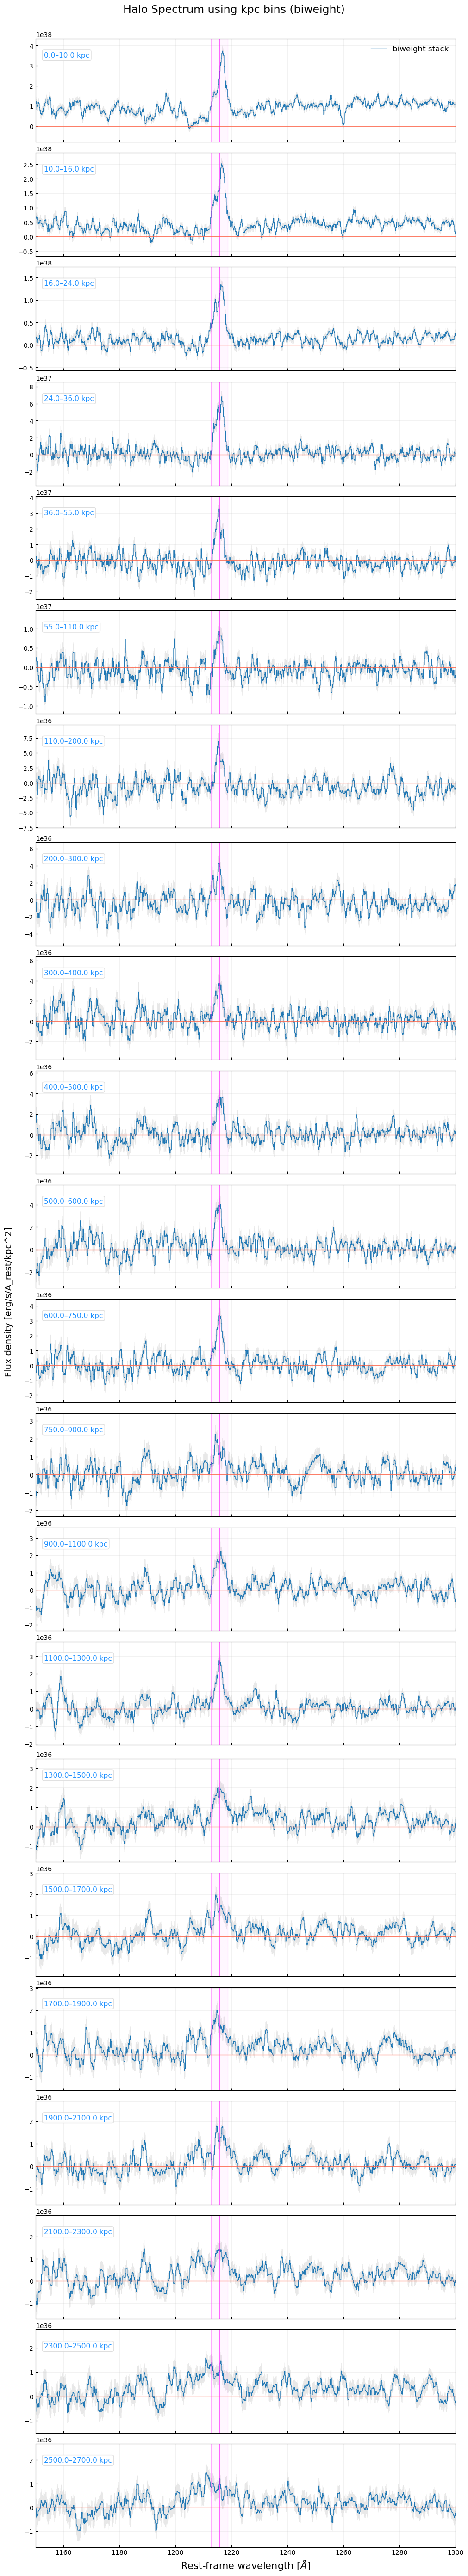

(<Figure size 1000x5500 with 22 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >,
        <Axes: xlabel='Rest-frame wavelength [$\\AA$]'>], dtype=object))

In [32]:
plotting.plot_stack_panels(stacks,
    method="biweight",
    distance_type=bin_mode,
    title=None,
    xlim=(1150, 1300),
    lya_window=half_width,
    figsize_width=10,
    panel_height=2.5,
    show_err=True,
    smooth=None,
    savepath=None,
    dpi=300)

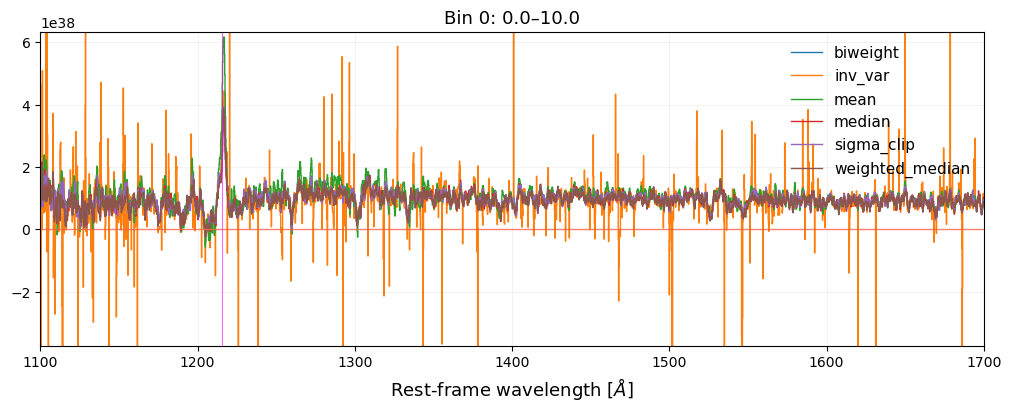

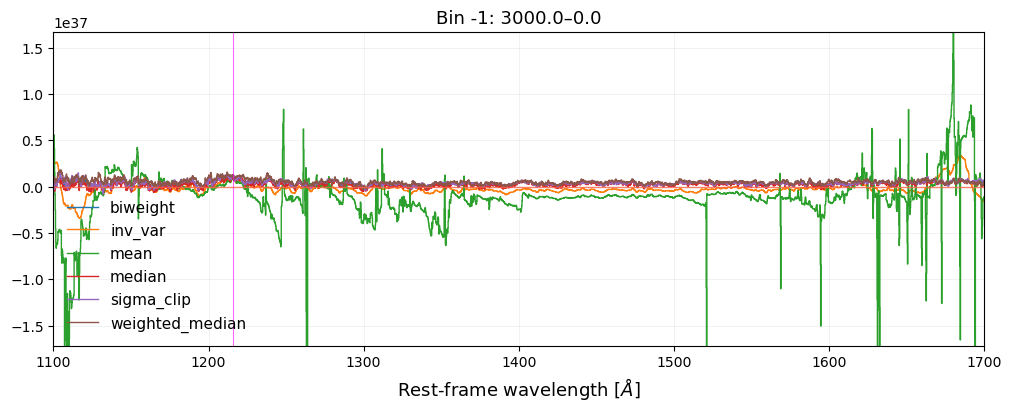

(<Figure size 1000x400 with 1 Axes>,
 <Axes: title={'center': 'Bin -1: 3000.0–0.0'}, xlabel='Rest-frame wavelength [$\\AA$]'>)

In [15]:
plotting.plot_methods_overlay(stacks,
    methods=None,
    radial_index=0,
    xlim=spexlim,
    smooth=None,
    title=None,
    set_ylim=True,
    ylim_pad=0.25,
    ylim_percentiles=(1, 99),
    include_zero=False)

plotting.plot_methods_overlay(stacks,
    methods=None,
    radial_index=-1,
    xlim=spexlim,
    smooth=None,
    title=None,
    set_ylim=True,
    ylim_pad=0.25,
    ylim_percentiles=(1, 99),
    include_zero=False)

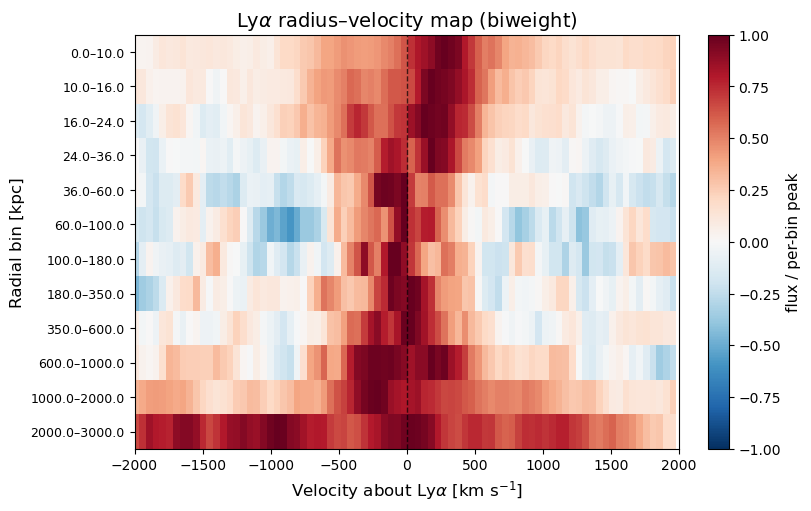

(<Figure size 800x500 with 2 Axes>,
 <Axes: title={'center': 'Ly$\\alpha$ radius–velocity map (biweight)'}, xlabel='Velocity about Ly$\\alpha$ [km s$^{-1}$]', ylabel='Radial bin [kpc]'>)

In [16]:
plotting.plot_radius_velocity_map(stacks,
    method="biweight",
    distance_type=bin_mode,
    vlim=(-2000, 2000),
    normalize="peak",
    cmap="RdBu_r",
    smooth=None,
    show_window=None,
    title=None,
    figsize=(8, 5),
    savepath=None,
    dpi=300)

# Bootstrap Pipeline

In [36]:
boot_b = measure.measure_all_bins(cfg2, stacks,
    seed=random_seed,
    verbose=True)

# flux_rf = stacks['cube_flux']
# err_rf  = stacks['cube_err']
# wave    = stacks['rest_wave']

# boot_m = measure.bootstrap_all(flux_rf, err_rf, wave,
#     nboot=cfg2.n_bootstrap,
#     bounds=cfg2.line_window,
#     stack_method="mean",
#     compute_side_ratio=True,
#     compute_stack_error=True,
#     robust_stack_error=True,
#     seed=random_seed, verbose=True,
#     weights=None,
#     sigma_clip_sigma=3.0, sigma_clip_maxiters=5,
# )

▶ bootstrap [median50]  |  nboot=2000  stack=biweight  centroid=median50  window=(1212.67,1218.67)  cont=median  side_ratio=True  stack_err=True  seed=10


bootstrap [median50]:   0%|          | 0/2000 [00:00<?, ?it/s]

In [37]:
boot = boot_b

       bin       v_fid±err    nσ≠0  flux S/N    ok%  notes
──────────────────────────────────────────────────────────
      0-10   +196.5± 25.2     7.8      10.6   100%  
     10-16   +131.8± 22.3     5.7      11.9   100%  
     16-24    +67.2± 25.6     2.6      12.6   100%  
     24-36    +45.0± 42.7     1.0      10.4   100%  
     36-55    -49.9± 34.7     1.5       7.2   100%  
    55-110    -17.1± 50.4     0.3       3.7   100%  consistent w/ 0
   110-200    -34.8± 46.0     0.7       4.9   100%  consistent w/ 0
   200-300    -86.0± 57.9     1.5       3.4   100%  
   300-400    -48.3± 61.0     0.7       4.0   100%  consistent w/ 0
   400-500    +30.3± 51.3     0.6       5.1   100%  consistent w/ 0
   500-600    -72.1± 55.8     1.2       3.4   100%  
   600-750     -8.1± 45.1     0.2       5.0   100%  consistent w/ 0
   750-900   -124.6± 90.8     1.1       3.2   100%  
  900-1100    +70.7± 68.3     0.9       4.0   100%  consistent w/ 0
 1100-1300    +12.8± 45.0     0.3       5.1   100%

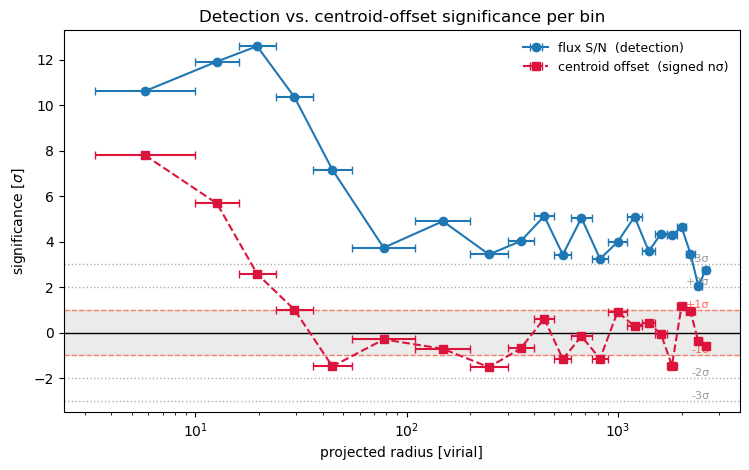

In [38]:
conf = analysis.measurement_confidence(boot, stacks)

#Plots BOTH curves; centroid is signed from boot["centroid_v_fid"]
fig, ax = plotting.plot_significance_comparison(conf, boot)

In [41]:
from dataclasses import replace
from utils_lya_halo.extract import combine_fibers

def rebin_product_radially(product, merge_groups):
    """Collapse product's radial axis via nfib-weighted combine, same convention
    as single_galaxy_spectra's merge_bins. merge_groups: index groups into the
    ORIGINAL r_edges, e.g. [[0],[1],[2,3],[4,5,6],...]. Run BEFORE build_stacks."""
    spec, err, nfib = map(np.asarray, (product.spec, product.err, product.nfib))
    r_edges = np.asarray(product.r_edges)
    ngal, nrad, nwave = spec.shape
    groups = [list(np.atleast_1d(g)) for g in merge_groups]
    new_spec = np.full((ngal, len(groups), nwave), np.nan)
    new_err  = np.full_like(new_spec, np.nan)
    new_nfib = np.zeros((ngal, len(groups)))
    new_edges = [r_edges[0]]
    for k, g in enumerate(groups):
        for i in range(ngal):
            w = nfib[i, g]
            new_spec[i, k], new_err[i, k] = combine_fibers(
                spec[i, g], err[i, g], method="weighted_median", weights=w)
            new_nfib[i, k] = np.sum(w)
        new_edges.append(r_edges[max(g) + 1])
    return replace(product, spec=new_spec, err=new_err, nfib=new_nfib,
                    r_edges=np.asarray(new_edges))

In [52]:
merge_groups = [
    [0], [1], [2], [3], [4],                
    [5, 6],                  
    [7, 8, 9],              
    [10, 11, 12],           
    [13, 14, 15, 16],           
    [17, 18, 19, 20, 21],
]

new_product = rebin_product_radially(prod_galaxy, merge_groups)
stacks_optimal = build_stacks(cfg2, new_product, keep_cube=True)

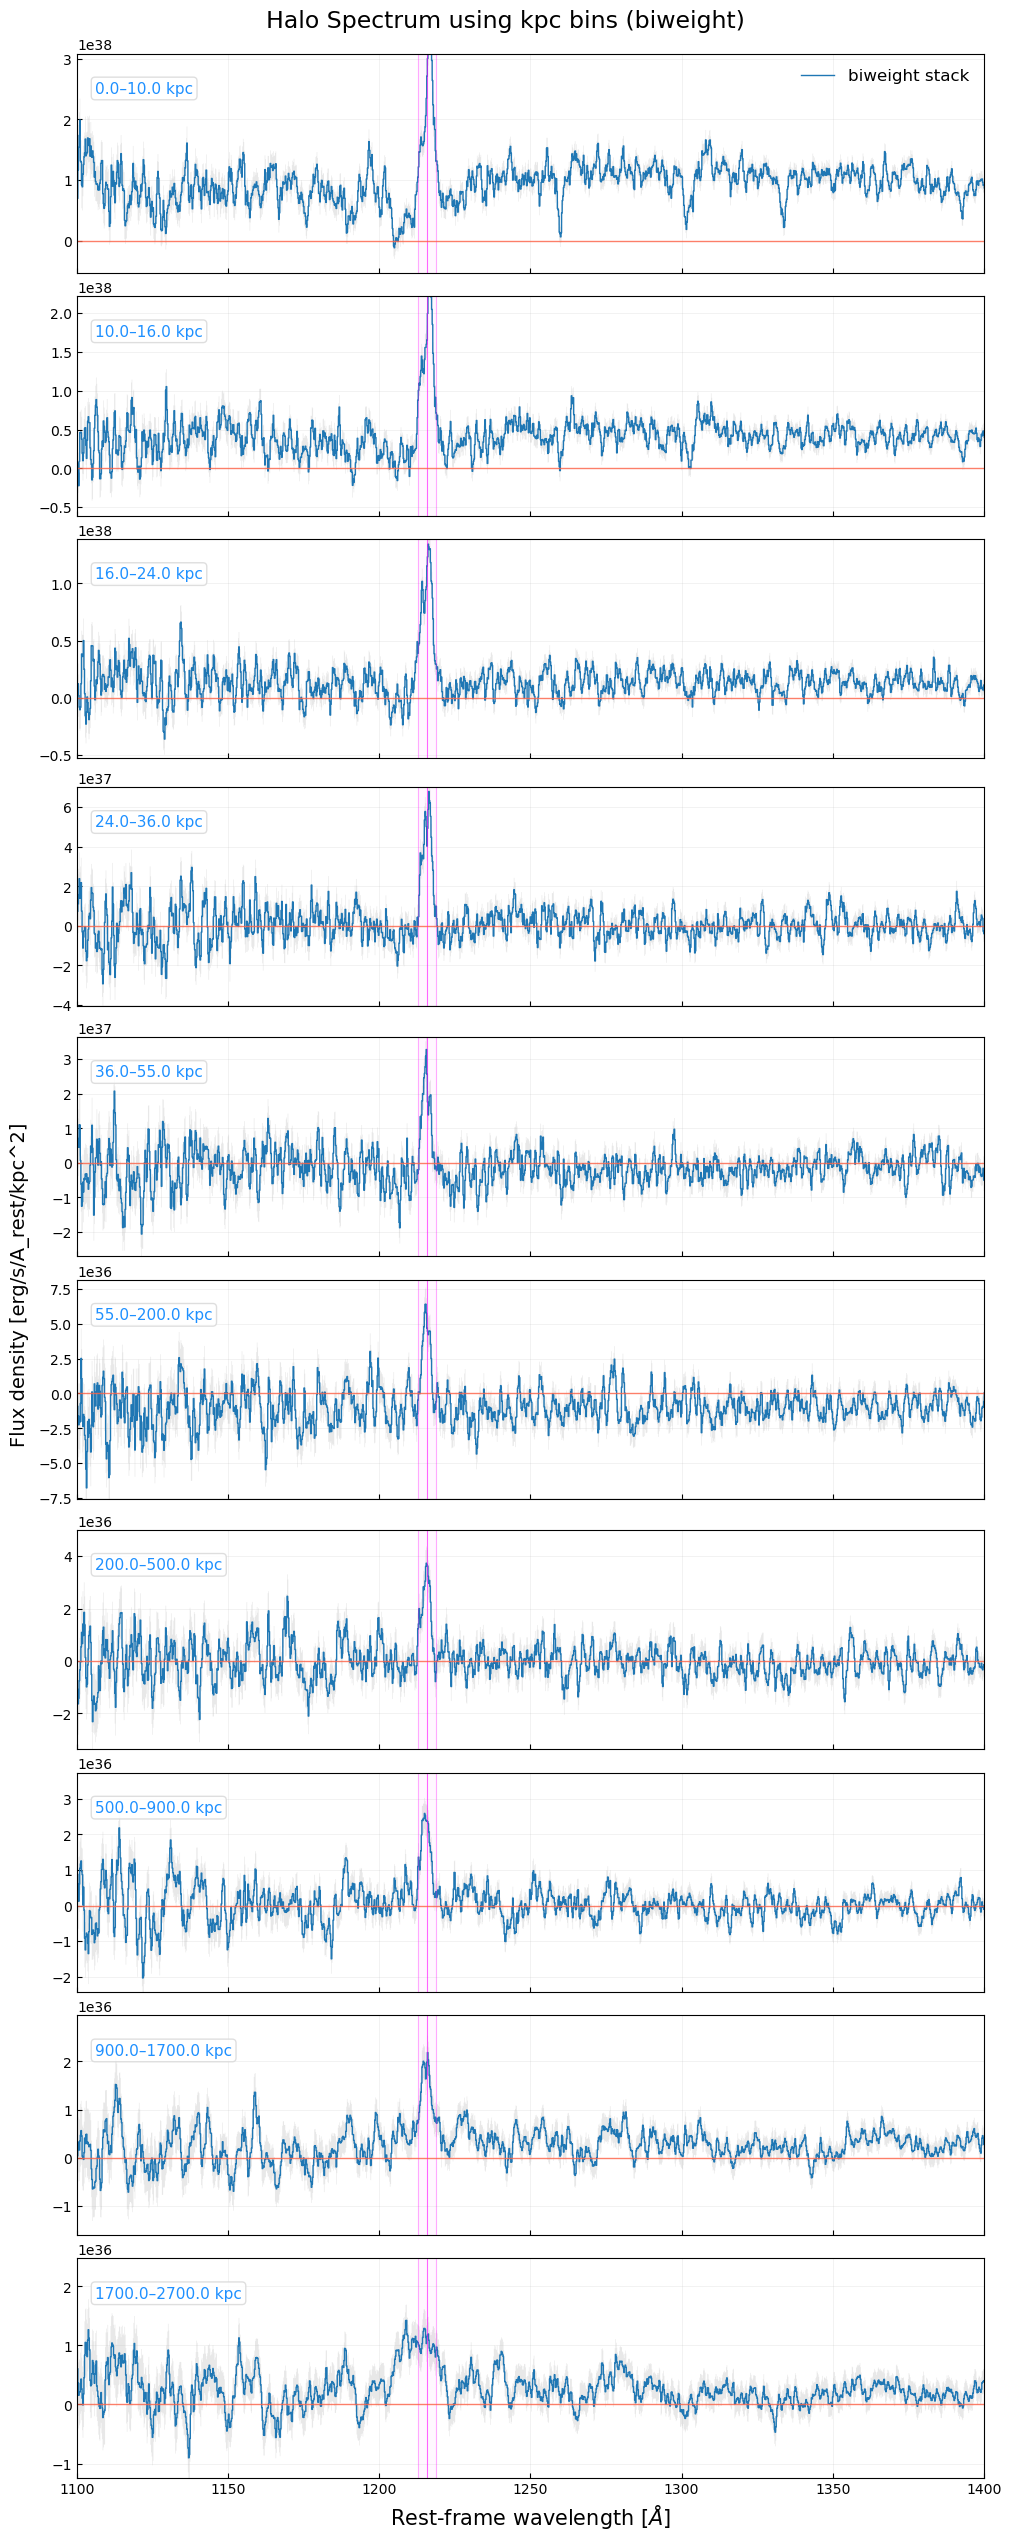

(<Figure size 1000x2500 with 10 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >,
        <Axes: xlabel='Rest-frame wavelength [$\\AA$]'>], dtype=object))

In [59]:
plotting.plot_stack_panels(stacks_optimal,
    method="biweight",
    distance_type=bin_mode,
    title=None,
    xlim=(1100, 1400),
    lya_window=half_width,
    figsize_width=10,
    panel_height=2.5,
    show_err=True,
    smooth=None,
    savepath=None,
    dpi=300)

In [54]:
boot_optimal = measure.measure_all_bins(cfg2, stacks_optimal,
    seed=random_seed,
    verbose=True)

▶ bootstrap [median50]  |  nboot=2000  stack=biweight  centroid=median50  window=(1212.67,1218.67)  cont=median  side_ratio=True  stack_err=True  seed=10


bootstrap [median50]:   0%|          | 0/2000 [00:00<?, ?it/s]

       bin       v_fid±err    nσ≠0  flux S/N    ok%  notes
──────────────────────────────────────────────────────────
      0-10   +196.5± 25.2     7.8      10.6   100%  
     10-16   +131.8± 22.3     5.7      11.9   100%  
     16-24    +67.2± 25.6     2.6      12.6   100%  
     24-36    +45.0± 42.7     1.0      10.4   100%  
     36-55    -49.9± 34.7     1.5       7.2   100%  
    55-200    -46.8± 42.2     1.0       6.2   100%  
   200-500    -42.3± 44.7     0.9       5.9   100%  consistent w/ 0
   500-900    -95.7± 48.0     1.8       5.8   100%  
  900-1700    -33.4± 57.9     0.6       4.8   100%  consistent w/ 0
 1700-2700    -33.8± 84.9     0.4       3.7   100%  consistent w/ 0

  flux S/N = galaxy-bootstrap stability of integrated flux (not photon S/N).
  nσ≠0 is a gut-check only; use validation.py for real significance.


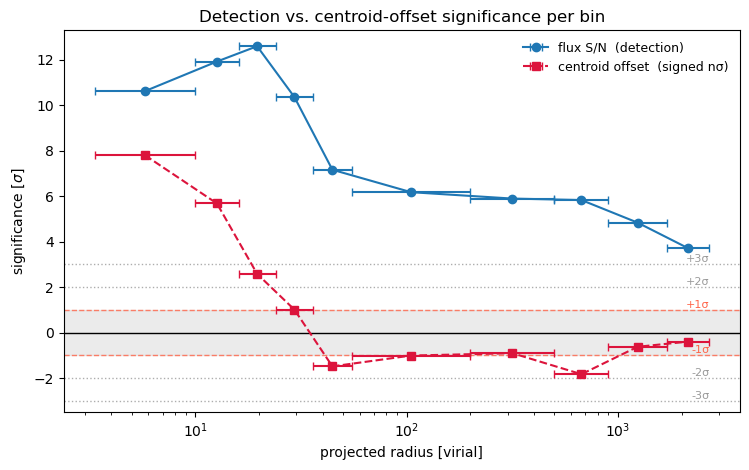

In [56]:
conf_optimal = analysis.measurement_confidence(boot_optimal, stacks_optimal)

#Plots BOTH curves; centroid is signed from boot["centroid_v_fid"]
fig, ax = plotting.plot_significance_comparison(conf_optimal, boot_optimal)

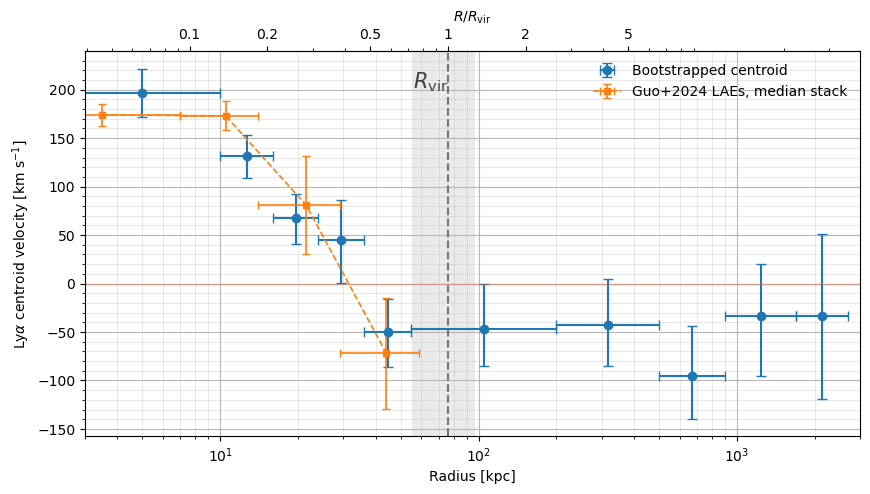

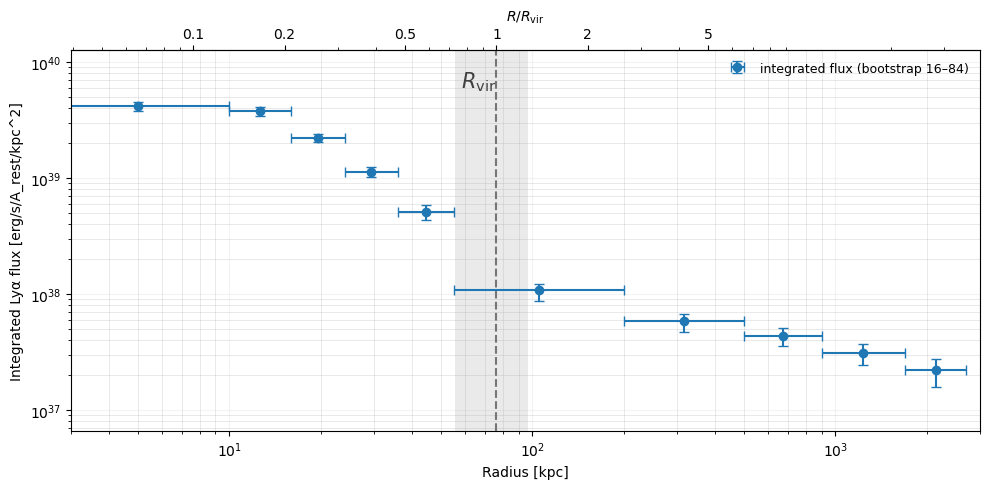

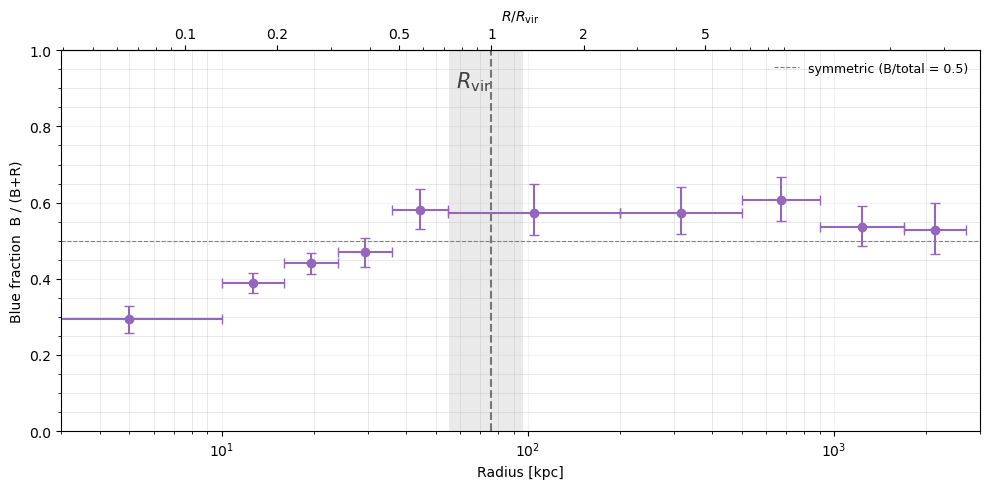

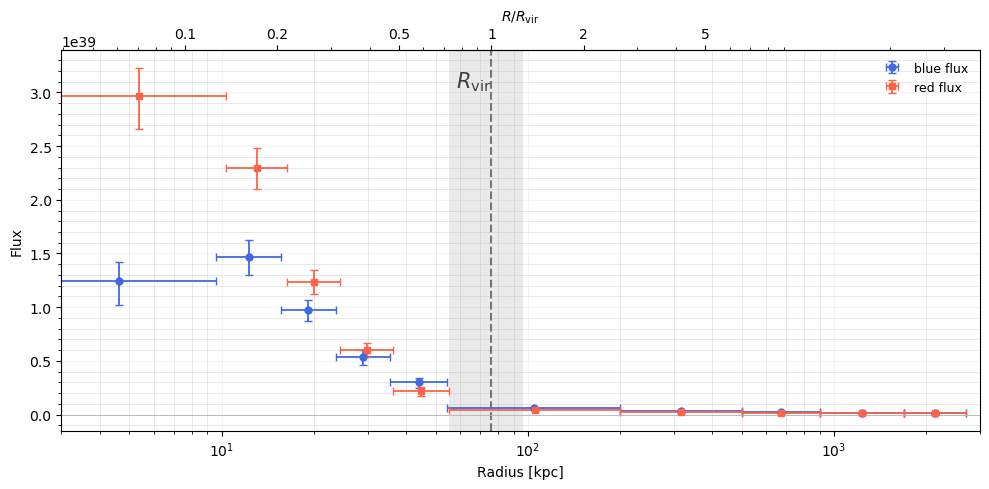

(<Figure size 1000x500 with 1 Axes>,
 <Axes: xlabel='Radius [kpc]', ylabel='Flux'>)

In [57]:
# Radial profiles
analysis.plot_centroid_profile(boot_optimal, stacks_optimal,
    ylims=None,
    xlims=xlims,
    show_vr=True,
    VR_biweight_error=None,
    plot_literature=True,
    figsize=(10, 5),
    title=None,                          # or a string; None = no title
    save_fig=False,
    save_name='Centroid_Profile')        # -> Centroid_Profile.png

analysis.plot_flux_profile(boot_optimal, stacks_optimal,
    ylims=None,
    xlims=xlims,
    show_vr=True,
    VR_biweight_error=None,
    figsize=(10, 5),
    title=None,
    save_fig=False,
    save_name='Surface_Luminosity_Profile')            # -> Flux_Profile.png

analysis.plot_asymmetry_profile(boot_optimal, stacks_optimal,
    xlims=xlims,
    panels='fraction',
    show_vr=True,
    VR_biweight_error=None,
    figsize=(10, 5),
    title1=None, 
    save_fig=False,
    save_name='Blue_Fraction')
analysis.plot_asymmetry_profile(boot_optimal, stacks_optimal,
    xlims=xlims,
    panels='flux',
    show_vr=True,
    VR_biweight_error=None,
    figsize=(10, 5),
    title2=None,
    save_fig=False,
    save_name='Asymmetry_Flux')